# MPRNet — SEMICON_Noise_v2 Denoising Benchmark

This self-contained Kaggle notebook trains **MPRNet** for same-resolution grayscale SEM restoration: noisy **1024×768** input to clean **1024×768** HR. It reads the published manifest and never creates new splits. The uploaded generator confirms 4,158 pairs, including single and combined degradations, with 2,910/831/417 train/validation/test identities.

## Architecture

**Type:** Multi-stage CNN restoration. Three progressive stages with supervised-attention feature transfer.

`Noisy SEM → shallow features → model-specific restoration trunk → residual clean prediction`

The implementation is intentionally compact rather than paper-maximal so a Kaggle T4 can complete a stable benchmark. Training uses aligned random patches; validation and testing use overlap-tiled full-resolution inference.

## Expected Kaggle T4 budget

| Item | Estimate |
|---|---:|
| Patch / batch | 192×192 / 2 |
| Peak VRAM | 8–11 GB |
| Epoch time | 5–8 min |
| 100 epochs | 9–14 h |

Times include a deterministic 96-image validation subset each epoch. The final test covers all 417 images; advanced IQA adds extra time and may require Kaggle Internet for `pyiqa` installation/weights. Actual timing varies with T4 contention and storage throughput.


## 1. Environment and reproducibility

AMP is enabled only on CUDA. Heavy perceptual/no-reference metric packages are not imported during training.

In [1]:
from __future__ import annotations
import gc, json, math, os, random, subprocess, sys, time
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

SEED=2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark=True
torch.backends.cuda.matmul.allow_tf32=True
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP=DEVICE.type=="cuda"
print("PyTorch",torch.__version__,"| device",DEVICE)
if AMP:
 print(torch.cuda.get_device_name(0),"|",round(torch.cuda.get_device_properties(0).total_memory/2**30,2),"GiB")


PyTorch 2.10.0+cu128 | device cuda
Tesla T4 | 14.56 GiB


## 2. Configuration

Model-specific patches and batches prioritize completion and stability over maximum capacity.

In [2]:
MODEL_NAME="MPRNet"
EPOCHS=100
PATCH_SIZE=192
BATCH_SIZE=2
WORKERS=2
LR=0.0002
TILE=256
VAL_SAMPLES=96
PATIENCE=20
MIN_DELTA=0.005
IS_GAN=False
GAN_WEIGHT=0.002
RESUME=True
CONFIG=dict(model=MODEL_NAME,epochs=EPOCHS,patch=PATCH_SIZE,batch=BATCH_SIZE,lr=LR,tile=TILE,val_samples=VAL_SAMPLES,seed=SEED)
print(CONFIG)

{'model': 'MPRNet', 'epochs': 100, 'patch': 192, 'batch': 2, 'lr': 0.0002, 'tile': 256, 'val_samples': 96, 'seed': 2026}


## 3. Manifest-defined paired dataset

The loader auto-detects SEMICON_Noise_v2, resolves manifest paths, loads images lazily, and applies synchronized crops/flips/rotations only to training pairs.

In [3]:
INPUT_ROOT=Path("/kaggle/input")
RUN_ROOT=Path("/kaggle/working")/MODEL_NAME
RUN_ROOT.mkdir(parents=True,exist_ok=True)

def samples(payload):
 if isinstance(payload,list): return payload
 if isinstance(payload,dict) and isinstance(payload.get("samples"),list): return payload["samples"]
 raise ValueError("Manifest must be a list or contain a samples list")

def locate_dataset():
 candidates=[]
 for p in INPUT_ROOT.rglob("manifest.json"):
  try:
   payload=json.loads(p.read_text(encoding="utf-8")); rows=samples(payload)
   cats=Counter(str(r.get("category","")).lower() for r in rows)
   splits=Counter(str(r.get("split","")).lower() for r in rows)
   text=(p.as_posix()+str(payload.get("dataset","") if isinstance(payload,dict) else "")).lower()
   score=100*int("noise" in text)+20*int(cats["single"]>0 and cats["combined"]>0)+len(rows)/10000
   if all(splits[x]>0 for x in ("train","val","test")): candidates.append((score,p,payload,rows))
  except Exception: pass
 if not candidates: raise FileNotFoundError("SEMICON_Noise_v2 manifest was not found under /kaggle/input")
 _,p,payload,rows=max(candidates,key=lambda x:x[0]); return p.parent,p,payload,rows

ROOT,MANIFEST,PAYLOAD,RECORDS=locate_dataset()
def split_name(v):
 v=str(v).lower(); return "val" if v in {"validation","valid"} else v
SPLITS={s:[r for r in RECORDS if split_name(r.get("split"))==s] for s in ("train","val","test")}
print("Dataset root:",ROOT); print("Manifest:",MANIFEST)
print("Split counts:",{k:len(v) for k,v in SPLITS.items()})
print("Categories:",Counter(str(r.get("category","unknown")) for r in RECORDS))
assert all(SPLITS.values())

def resolve(value):
 p=Path(str(value))
 for q in (p,ROOT/p):
  if q.is_file(): return q
 hits=list(ROOT.rglob(p.name))
 if len(hits)==1:return hits[0]
 raise FileNotFoundError(value)

def pair_paths(r):
 return resolve(r.get("lr_path") or r.get("noisy_path")),resolve(r.get("hr_path") or r.get("clean_path"))

class SEMICONPairs(Dataset):
 def __init__(self,rows,train=False): self.rows=rows; self.train=train
 def __len__(self): return len(self.rows)
 def __getitem__(self,i):
  r=self.rows[i]; lp,hp=pair_paths(r)
  with Image.open(lp) as im: noisy=np.asarray(im.convert("L"),dtype=np.float32)/255.
  with Image.open(hp) as im: clean=np.asarray(im.convert("L"),dtype=np.float32)/255.
  if noisy.shape!=clean.shape: raise ValueError(f"Pair shape mismatch: {lp} {noisy.shape} vs {hp} {clean.shape}")
  if self.train:
   # Worker RNG changes every epoch while remaining reproducible from the seeded loader.
   rng=np.random.default_rng((torch.initial_seed()+i)%2**32)
   c=min(PATCH_SIZE,*noisy.shape); y=int(rng.integers(0,noisy.shape[0]-c+1)); x=int(rng.integers(0,noisy.shape[1]-c+1))
   noisy=noisy[y:y+c,x:x+c]; clean=clean[y:y+c,x:x+c]
   if rng.random()<.5: noisy=np.fliplr(noisy); clean=np.fliplr(clean)
   if rng.random()<.5: noisy=np.flipud(noisy); clean=np.flipud(clean)
   k=int(rng.integers(0,4)); noisy=np.rot90(noisy,k); clean=np.rot90(clean,k)
  return {"noisy":torch.from_numpy(np.ascontiguousarray(noisy))[None],"clean":torch.from_numpy(np.ascontiguousarray(clean))[None],"id":str(r.get("sample_id",i))}

def seed_worker(worker_id):
 s=(SEED+worker_id)%2**32; random.seed(s); np.random.seed(s)
g=torch.Generator().manual_seed(SEED)
train_ds=SEMICONPairs(SPLITS["train"],True)
# A fixed stratification-spanning validation subset keeps 100 epochs feasible; final testing is complete.
val_full=SEMICONPairs(SPLITS["val"])
val_idx=np.linspace(0,len(val_full)-1,min(VAL_SAMPLES,len(val_full)),dtype=int).tolist()
val_ds=Subset(val_full,val_idx); test_ds=SEMICONPairs(SPLITS["test"])
loader_args=dict(num_workers=WORKERS,pin_memory=AMP,persistent_workers=WORKERS>0)
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,drop_last=True,worker_init_fn=seed_worker,generator=g,**loader_args)
val_loader=DataLoader(val_ds,batch_size=1,shuffle=False,**loader_args)
test_loader=DataLoader(test_ds,batch_size=1,shuffle=False,**loader_args)
b=next(iter(train_loader)); print("Training tensors:",b["noisy"].shape,b["clean"].shape,"| validation samples/epoch:",len(val_ds))


Dataset root: /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_Noise_v2/SEMICON_Noise_v2
Manifest: /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_Noise_v2/SEMICON_Noise_v2/manifest.json
Split counts: {'train': 2910, 'val': 831, 'test': 417}
Categories: Counter({'single': 2080, 'combined': 2078})
Training tensors: torch.Size([2, 1, 192, 192]) torch.Size([2, 1, 192, 192]) | validation samples/epoch: 96


## 4. Model implementation

This is a complete compact implementation of the named architecture family, adapted to one-channel same-resolution restoration.

In [4]:
class ResBlock(nn.Module):
 def __init__(self,c,scale=1.): super().__init__(); self.body=nn.Sequential(nn.Conv2d(c,c,3,1,1),nn.ReLU(True),nn.Conv2d(c,c,3,1,1)); self.scale=scale
 def forward(self,x): return x+self.body(x)*self.scale
class CALayer(nn.Module):
 def __init__(self,c,r=8): super().__init__(); self.m=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Conv2d(c,max(4,c//r),1),nn.ReLU(True),nn.Conv2d(max(4,c//r),c,1),nn.Sigmoid())
 def forward(self,x): return x*self.m(x)
class CAB(nn.Module):
 def __init__(self,c): super().__init__(); self.m=nn.Sequential(nn.Conv2d(c,c,3,1,1),nn.GELU(),nn.Conv2d(c,c,3,1,1),CALayer(c))
 def forward(self,x): return x+self.m(x)
class LayerNorm2d(nn.Module):
 def __init__(self,c): super().__init__(); self.w=nn.Parameter(torch.ones(1,c,1,1)); self.b=nn.Parameter(torch.zeros(1,c,1,1))
 def forward(self,x):
  v=x.var(1,keepdim=True,unbiased=False); m=x.mean(1,keepdim=True); return (x-m)/torch.sqrt(v+1e-5)*self.w+self.b

class SAM(nn.Module):
 def __init__(self,c): super().__init__(); self.i=nn.Conv2d(c,1,3,1,1); self.f=nn.Conv2d(1,c,3,1,1); self.a=nn.Conv2d(1,c,3,1,1)
 def forward(self,x,img): out=img+self.i(x); att=torch.sigmoid(self.a(out)); return x*att+self.f(img),out
class Stage(nn.Module):
 def __init__(self,c,n=5): super().__init__(); self.h=nn.Conv2d(1,c,3,1,1); self.b=nn.Sequential(*[CAB(c) for _ in range(n)]); self.sam=SAM(c)
 def forward(self,img,extra=None): x=self.h(img); x=x if extra is None else x+extra; return self.sam(self.b(x),img)
class Model(nn.Module):
 def __init__(self,c=32): super().__init__(); self.s1=Stage(c); self.s2=Stage(c); self.h=nn.Conv2d(1,c,3,1,1); self.b=nn.Sequential(*[CAB(c) for _ in range(7)]); self.o=nn.Conv2d(c,1,3,1,1)
 def forward(self,x): f1,o1=self.s1(x); f2,o2=self.s2(x,f1); return x+self.o(self.b(self.h(x)+f2))


## 5. AMP training, validation, checkpoints, and resume

Best weights are selected strictly by validation PSNR. `last.pth` contains optimizer, scheduler, scaler, history, and early-stopping state for exact resume.

In [5]:
model=Model().to(DEVICE)
discriminator=Discriminator().to(DEVICE) if IS_GAN else None
params=sum(p.numel() for p in model.parameters() if p.requires_grad); print("Generator parameters:",f"{params:,}")
optimizer=torch.optim.AdamW(model.parameters(),lr=LR,betas=(.9,.99),weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=LR*.01)
scaler=torch.amp.GradScaler("cuda",enabled=AMP)
if IS_GAN:
 d_optimizer=torch.optim.AdamW(discriminator.parameters(),lr=LR,betas=(.5,.999)); d_scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(d_optimizer,T_max=EPOCHS,eta_min=LR*.01)

def metric_values(p,y):
 p=p.clamp(0,1).float(); y=y.float(); mse=((p-y)**2).flatten(1).mean(1); mae=(p-y).abs().flatten(1).mean(1); psnr=-10*torch.log10(mse.clamp_min(1e-12))
 # Windowed SSIM, calculated on-device without retaining predictions.
 mu1=F.avg_pool2d(p,11,1,5); mu2=F.avg_pool2d(y,11,1,5); s1=F.avg_pool2d(p*p,11,1,5)-mu1**2; s2=F.avg_pool2d(y*y,11,1,5)-mu2**2; s12=F.avg_pool2d(p*y,11,1,5)-mu1*mu2
 ssim=((2*mu1*mu2+.01**2)*(2*s12+.03**2)/((mu1**2+mu2**2+.01**2)*(s1+s2+.03**2))).flatten(1).mean(1)
 return psnr.mean().item(),ssim.mean().item(),mae.mean().item(),mse.mean().item()

@torch.inference_mode()
def tiled(x,tile=TILE,overlap=32):
 b,c,h,w=x.shape
 if h<=tile and w<=tile:return model(x)
 out=torch.zeros((b,1,h,w),device=x.device); weight=torch.zeros_like(out); step=tile-overlap
 ys=list(range(0,max(1,h-tile+1),step)); xs=list(range(0,max(1,w-tile+1),step))
 if not ys or ys[-1]!=h-tile:ys.append(max(0,h-tile))
 if not xs or xs[-1]!=w-tile:xs.append(max(0,w-tile))
 for yy in ys:
  for xx in xs:
   q=x[:,:,yy:yy+tile,xx:xx+tile]; out[:,:,yy:yy+q.shape[-2],xx:xx+q.shape[-1]]+=model(q); weight[:,:,yy:yy+q.shape[-2],xx:xx+q.shape[-1]]+=1
 return out/weight.clamp_min(1)

@torch.inference_mode()
def validate():
 model.eval(); sums=np.zeros(5); n=0
 for b in tqdm(val_loader,desc="validation",leave=False):
  x=b["noisy"].to(DEVICE,non_blocking=True); y=b["clean"].to(DEVICE,non_blocking=True)
  with torch.amp.autocast("cuda",enabled=AMP): p=tiled(x).clamp(0,1); loss=F.l1_loss(p,y)
  ps,ss,ma,ms=metric_values(p,y); sums+=np.array([loss.item(),ps,ss,ma,ms]); n+=1
 return dict(zip(["val_loss","psnr","ssim","mae","mse"],sums/max(n,1)))

best=-1.; wait=0; history=[]; start=1; best_path=RUN_ROOT/"best.pth"; last_path=RUN_ROOT/"last.pth"
if RESUME and last_path.is_file():
 ck=torch.load(last_path,map_location=DEVICE,weights_only=False); model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"]); start=ck["epoch"]+1; best=ck["best"]; wait=ck["wait"]; history=ck["history"]
 if IS_GAN: discriminator.load_state_dict(ck["discriminator"]); d_optimizer.load_state_dict(ck["d_optimizer"]); d_scheduler.load_state_dict(ck["d_scheduler"])
 print("Resuming at epoch",start)

for epoch in range(start,EPOCHS+1):
 t0=time.perf_counter(); model.train(); total=0.; seen=0
 for b in tqdm(train_loader,desc=f"{MODEL_NAME} {epoch:03d}/{EPOCHS}"):
  x=b["noisy"].to(DEVICE,non_blocking=True); y=b["clean"].to(DEVICE,non_blocking=True)
  if IS_GAN:
   discriminator.train()
   with torch.amp.autocast("cuda",enabled=AMP): fake=model(x); real_o=discriminator(torch.cat([x,y],1)); fake_o=discriminator(torch.cat([x,fake.detach()],1)); dl=0.
   ro=[z[-1] for z in real_o]; fo=[z[-1] for z in fake_o]; dl=sum(F.binary_cross_entropy_with_logits(a,torch.ones_like(a))+F.binary_cross_entropy_with_logits(b0,torch.zeros_like(b0)) for a,b0 in zip(ro,fo))/(2*len(ro))
   d_optimizer.zero_grad(set_to_none=True); scaler.scale(dl).backward(); scaler.unscale_(d_optimizer); nn.utils.clip_grad_norm_(discriminator.parameters(),1.0); scaler.step(d_optimizer)
  with torch.amp.autocast("cuda",enabled=AMP): p=model(x); rec=F.l1_loss(p,y); loss=rec
  if IS_GAN:
   fo=discriminator(torch.cat([x,p],1)); adv=sum(F.binary_cross_entropy_with_logits(z[-1],torch.ones_like(z[-1])) for z in fo)/len(fo); loss=rec+GAN_WEIGHT*adv
  optimizer.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(optimizer); scaler.update(); total+=loss.item()*x.size(0); seen+=x.size(0)
 scheduler.step()
 if IS_GAN:d_scheduler.step()
 v=validate(); row={"epoch":epoch,"train_loss":total/max(seen,1),"lr":optimizer.param_groups[0]["lr"],"epoch_minutes":(time.perf_counter()-t0)/60,**v}; history.append(row); pd.DataFrame(history).to_csv(RUN_ROOT/"training_history.csv",index=False)
 improved=v["psnr"]>best+MIN_DELTA
 if improved: best=v["psnr"]; wait=0; torch.save({"model":model.state_dict(),"epoch":epoch,"metrics":v,"config":CONFIG},best_path)
 else: wait+=1
 state={"epoch":epoch,"model":model.state_dict(),"optimizer":optimizer.state_dict(),"scheduler":scheduler.state_dict(),"scaler":scaler.state_dict(),"best":best,"wait":wait,"history":history}
 if IS_GAN: state.update(discriminator=discriminator.state_dict(),d_optimizer=d_optimizer.state_dict(),d_scheduler=d_scheduler.state_dict())
 torch.save(state,last_path); print(row,"| early-stop",wait,"/",PATIENCE)
 gc.collect()
 if AMP: print("GPU peak GiB",round(torch.cuda.max_memory_allocated()/2**30,2)); torch.cuda.empty_cache()
 if wait>=PATIENCE: print("Early stopping"); break


Generator parameters: 322,503


MPRNet 001/100:   0%|          | 0/1455 [00:00<?, ?it/s]

validation:   0%|          | 0/96 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.0860402309691015, 'lr': 0.00019995114947620745, 'epoch_minutes': 1.86521079005, 'val_loss': np.float64(0.07714672263440055), 'psnr': np.float64(19.702180465062458), 'ssim': np.float64(0.5181551950518042), 'mae': np.float64(0.07714672263440055), 'mse': np.float64(0.020389704859856767)} | early-stop 0 / 20
GPU peak GiB 0.84


MPRNet 002/100:   0%|          | 0/1455 [00:00<?, ?it/s]

...

validation:   0%|          | 0/96 [00:00<?, ?it/s]

{'epoch': 96, 'train_loss': 0.05747321846533272, 'lr': 2.780644569866702e-06, 'epoch_minutes': 1.5796286167499904, 'val_loss': np.float64(0.06437378223927226), 'psnr': np.float64(20.85167223215103), 'ssim': np.float64(0.5820073708891869), 'mae': np.float64(0.06437378223927226), 'mse': np.float64(0.015963441563902354)} | early-stop 19 / 20
GPU peak GiB 0.84


MPRNet 097/100:   0%|          | 0/1455 [00:00<?, ?it/s]

validation:   0%|          | 0/96 [00:00<?, ?it/s]

{'epoch': 97, 'train_loss': 0.056941054012671216, 'lr': 2.439365504295081e-06, 'epoch_minutes': 1.5784086593333388, 'val_loss': np.float64(0.0642788983459468), 'psnr': np.float64(20.857633143663406), 'ssim': np.float64(0.5825233086167524), 'mae': np.float64(0.0642788983459468), 'mse': np.float64(0.015905076637106202)} | early-stop 20 / 20
GPU peak GiB 0.84
Early stopping


## 6. Best-checkpoint test and reporting

The full test split is evaluated only after loading `best.pth`. PSNR, SSIM, MAE, MSE, RMSE, and entropy stream without retaining images. NIQE, BRISQUE, PIQE, and FSIM are loaded and computed only after training.

complete final test:   0%|          | 0/417 [00:00<?, ?it/s]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 80.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.2/226.2 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.4/99.4 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 470.6/470.6 kB 23.3 MB/s eta 0:00:00
Downloading: "https://huggingface.co/chaofengc/IQA

100%|██████████| 8.15k/8.15k [00:00<00:00, 18.0MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to /root/.cache/torch/hub/pyiqa/brisque_svm_weights.pth



100%|██████████| 112k/112k [00:00<00:00, 467kB/s]


final IQA metrics:   0%|          | 0/417 [00:00<?, ?it/s]

,model,parameters,avg_inference_seconds,fps,peak_gpu_gib,psnr,ssim,mae,mse,rmse,entropy,niqe,brisque,piqe,fsim
0,MPRNet,322503,0.242578,4.122383,0.842541,20.609444,0.557435,0.066371,0.016329,0.112683,6.465838,6.186444,26.557734,32.790568,0.838036


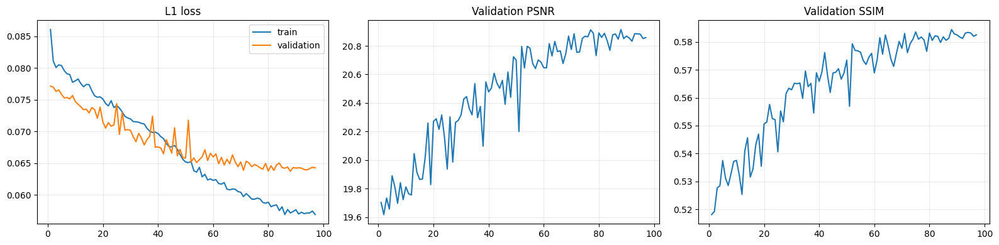

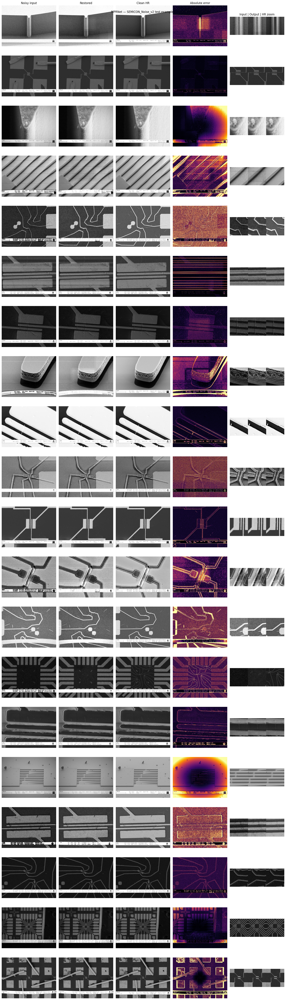

Outputs saved to /kaggle/working/MPRNet


In [6]:
ck=torch.load(best_path,map_location=DEVICE,weights_only=False); model.load_state_dict(ck["model"]); model.eval()

def entropy(x):
 a=(x.clamp(0,1)*255).byte().cpu().numpy().ravel(); h=np.bincount(a,minlength=256).astype(float); q=h[h>0]/h.sum(); return float(-(q*np.log2(q)).sum())

rows=[]; times=[]
with torch.inference_mode():
 for b in tqdm(test_loader,desc="complete final test"):
  x=b["noisy"].to(DEVICE,non_blocking=True); y=b["clean"].to(DEVICE,non_blocking=True)
  if AMP: torch.cuda.synchronize()
  t=time.perf_counter()
  with torch.amp.autocast("cuda",enabled=AMP): p=tiled(x).clamp(0,1)
  if AMP: torch.cuda.synchronize()
  times.append(time.perf_counter()-t); ps,ss,ma,ms=metric_values(p,y)
  rows.append({"sample_id":b["id"][0],"psnr":ps,"ssim":ss,"mae":ma,"mse":ms,"rmse":math.sqrt(ms),"entropy":entropy(p)})
per_image=pd.DataFrame(rows)

# Heavy IQA models are deliberately loaded only now, never during training/validation.
RUN_ADVANCED_IQA=True
if RUN_ADVANCED_IQA:
 try:
  import pyiqa
 except ImportError:
  subprocess.check_call([sys.executable,"-m","pip","install","-q","pyiqa"]); import pyiqa
 available=set(pyiqa.list_models()); names={"niqe":"niqe","brisque":"brisque","piqe":"piqe","fsim":"fsim"}
 missing=[v for v in names.values() if v not in available]
 if missing: raise RuntimeError(f"pyiqa does not provide required metrics: {missing}")
 iq={k:pyiqa.create_metric(v,device=DEVICE) for k,v in names.items()}; extra={k:[] for k in names}
 with torch.inference_mode():
  for b in tqdm(test_loader,desc="final IQA metrics"):
   x=b["noisy"].to(DEVICE); y=b["clean"].to(DEVICE); p=tiled(x).clamp(0,1); rgb=p.repeat(1,3,1,1); ref=y.repeat(1,3,1,1)
   for k,m in iq.items(): extra[k].append(float(m(rgb,ref).mean()) if k=="fsim" else float(m(rgb).mean()))
 for k,v in extra.items(): per_image[k]=v
 del iq; gc.collect()
 if AMP: torch.cuda.empty_cache()
per_image.to_csv(RUN_ROOT/"per_image_metrics.csv",index=False)
summary={"model":MODEL_NAME,"parameters":params,"avg_inference_seconds":float(np.mean(times)),"fps":float(1/np.mean(times)),"peak_gpu_gib":float(torch.cuda.max_memory_allocated()/2**30) if AMP else 0.}
for c in per_image.columns[1:]: summary[c]=float(per_image[c].mean())
pd.DataFrame([summary]).to_csv(RUN_ROOT/"test_results.csv",index=False); display(pd.DataFrame([summary]))

h=pd.DataFrame(history); fig,ax=plt.subplots(1,3,figsize=(16,4)); ax[0].plot(h.epoch,h.train_loss,label="train"); ax[0].plot(h.epoch,h.val_loss,label="validation"); ax[0].legend(); ax[0].set_title("L1 loss"); ax[1].plot(h.epoch,h.psnr); ax[1].set_title("Validation PSNR"); ax[2].plot(h.epoch,h.ssim); ax[2].set_title("Validation SSIM"); [a.grid(alpha=.25) for a in ax]; fig.tight_layout(); fig.savefig(RUN_ROOT/"training_curves.png",dpi=180); plt.show()

@torch.inference_mode()
def show_examples(n=20):
 ids=np.random.default_rng(SEED).choice(len(test_ds),n,replace=False); fig,axes=plt.subplots(n,5,figsize=(17,3*n))
 for r,i in enumerate(ids):
  b=test_ds[int(i)]; x=b["noisy"][None].to(DEVICE); y=b["clean"][None].to(DEVICE); p=tiled(x).clamp(0,1); a=x[0,0].cpu().numpy(); z=p[0,0].cpu().numpy(); gt=y[0,0].cpu().numpy(); err=np.abs(z-gt); yy=(gt.shape[0]-192)//2; xx=(gt.shape[1]-192)//2
  arr=[a,z,gt,err,np.concatenate([a[yy:yy+192,xx:xx+192],z[yy:yy+192,xx:xx+192],gt[yy:yy+192,xx:xx+192]],1)]; titles=["Noisy input","Restored","Clean HR","Absolute error","Input | Output | HR zoom"]
  for c,(im,t) in enumerate(zip(arr,titles)): axes[r,c].imshow(im,cmap="inferno" if c==3 else "gray",vmin=0,vmax=.2 if c==3 else 1); axes[r,c].axis("off"); axes[r,c].set_title(t if r==0 else "")
 fig.suptitle(MODEL_NAME+" — SEMICON_Noise_v2 test examples"); fig.tight_layout(); fig.savefig(RUN_ROOT/"visual_comparisons.png",dpi=140,bbox_inches="tight"); plt.show()
show_examples()
print("Outputs saved to",RUN_ROOT)


## 7. Practical interpretation

Use PSNR/SSIM for fidelity ranking and inspect error maps for semiconductor edge preservation. NIQE, BRISQUE, and PIQE were designed around natural-image statistics, so treat them as secondary diagnostics for SEM—not as sole selection criteria. GAN outputs require particular care because plausible-looking texture may be metrologically false.